# Gold Assistant — Retrieval Evaluation with Ground Truth v2 + Cloudflare Workers AI

Notebook นี้ใช้ประเมิน Chunking Methods 5 แบบจาก `ground_truth_queries_v2.jsonl` โดยเรียก Embedding Model `@cf/baai/bge-m3` ผ่าน Cloudflare Workers AI

## วัดผลอะไรบ้าง

1. **Corpus / evidence coverage** — Ground-truth source documents และ quotes อยู่ใน Chunk Collections ของแต่ละ Method หรือไม่
2. **Retrieval** — `Document Hit@K`, `Document Recall@K`, `Evidence Hit@K`, `Evidence Recall@K`, `Evidence MRR@10`
3. **Fact support** — Numeric value, unit, report period, publication date และ source attribution ที่พบใน Top-K
4. **แยก End-to-end ออกจาก Conditional Accuracy** — แสดงทั้งอัตราที่ค้น Source ถูกเจอ และความถูกต้องของ Fact *เมื่อค้น Source ที่ถูกต้องเจอแล้ว* เพื่อไม่ให้ Accuracy ที่คำนวณเฉพาะ Candidate ที่ผ่านการคัด Source กลบปัญหา Retrieval

> **ข้อจำกัดของ Ground Truth v2:** ทุก Query อยู่ในสถานะ `source_span_validated_needs_human_semantic_review` และ `judgment_set_exhaustive=false` ดังนั้นผลนี้เป็น *provisional benchmark* เท่านั้น `known-evidence precision` เป็นค่าต่ำสุดโดยประมาณ เพราะ Evidence ที่ระบุไว้อาจไม่ได้ครอบคลุมทุก Chunk ที่เกี่ยวข้อง

## ต้องมีไฟล์ Chunk Collections อยู่ก่อน

ค่าเริ่มต้นคาดว่าจะมีไฟล์เหล่านี้ใต้ `artifacts/chunking_benchmark/`:

- `chunks_existing_baseline.jsonl`
- `chunks_recursive_fixed.jsonl`
- `chunks_structure_aware.jsonl`
- `chunks_semantic.jsonl`
- `chunks_adaptive.jsonl`

ถ้าคุณเก็บไฟล์ไว้ที่อื่น ให้แก้ `CHUNK_DIR` ใน Cell Configuration ด้านล่าง

## 0. ติดตั้ง dependencies

รันครั้งแรกใน environment ที่ใช้เปิด Notebook เท่านั้น

In [5]:
#%uv pip install numpy pandas requests python-dotenv matplotlib tabulate


## 1. Imports และการตั้งค่า Path

Path ของ Ground Truth ใช้ตามที่คุณให้มา: `D:\Project_Github\gold assisstant\embedding\ground_truth_queries_v2.jsonl`

In [6]:
from pathlib import Path
import os
import json
import re
import time
import math
import sqlite3
import hashlib
import unicodedata
from collections import defaultdict, Counter
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

# ===== Paths: ปรับเฉพาะส่วนนี้หากโครงสร้างโฟลเดอร์ไม่ตรง =====
PROJECT_ROOT = Path(r"D:\Project_Github\gold assisstant")
EMBEDDING_DIR = PROJECT_ROOT / "embedding"
GT_PATH = EMBEDDING_DIR / "embedding" / "ground_truth_queries_v2.jsonl"
CHUNK_DIR = PROJECT_ROOT / "artifacts" / "chunking_benchmark"
CHUNK_DIR_CANDIDATES = [
    CHUNK_DIR,
    PROJECT_ROOT / "vector_database" / "embedding" / "chunking_benchmark",
    EMBEDDING_DIR / "artifacts" / "chunking_benchmark",
]
OUTPUT_DIR = EMBEDDING_DIR / "embedding" / "retrieval_eval_v2"
CACHE_PATH = OUTPUT_DIR / "cloudflare_embedding_cache.sqlite"

# ===== Experiment settings =====
EMBEDDING_MODEL = "@cf/baai/bge-m3"
METHODS = [
    "existing_baseline",
    "recursive_fixed",
    "structure_aware",
    "semantic",
    "adaptive",
]
for candidate_dir in CHUNK_DIR_CANDIDATES:
    if all((candidate_dir / f"chunks_{method}.jsonl").is_file() for method in METHODS):
        CHUNK_DIR = candidate_dir
        break
K_VALUES = [1, 3, 5, 10]
MAX_K = max(K_VALUES)
EMBED_BATCH_SIZE = 16
REQUEST_TIMEOUT_SECONDS = 120
MAX_RETRIES = 5
REQUEST_PAUSE_SECONDS = 0.15

# False = ไม่ใช้ source_filter จาก Ground Truth เป็นตัวกรอง Retrieval (ป้องกัน oracle leakage)
APPLY_GOLD_SOURCE_FILTER = False

# ปล่อย None เพื่อใช้ทุก split และรายงานแยก split; ตัวอย่าง: {"test"}
SPLITS_TO_EVALUATE = None

# ชื่อ Source ใน Ground Truth อาจต่างจากชื่อ Source ใน Chunk export
SOURCE_ALIASES = {
    "thaipbs_direct": "thaipbs",
    "thaipbs": "thaipbs",
    "fed": "fed",
    "bls_cpi": "bls_cpi",
    "bls_nfp": "bls_nfp",
}

# โหลด .env จาก Project Root และโฟลเดอร์ embedding (ห้ามใส่ token ใน Notebook)
for env_path in [PROJECT_ROOT / ".env", EMBEDDING_DIR / ".env", GT_PATH.parent / ".env"]:
    if env_path.exists():
        load_dotenv(env_path, override=False)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Ground Truth:", GT_PATH, "exists=", GT_PATH.exists())
print("Chunk directory:", CHUNK_DIR, "exists=", CHUNK_DIR.exists())
print("Available chunk directories:", [str(path) for path in CHUNK_DIR_CANDIDATES if path.exists()])
print("Output directory:", OUTPUT_DIR)
print("Embedding model:", EMBEDDING_MODEL)
print("Ground Truth Queries:", GT_PATH)

Project root: D:\Project_Github\gold assisstant
Ground Truth: D:\Project_Github\gold assisstant\embedding\embedding\ground_truth_queries_v2.jsonl exists= True
Chunk directory: D:\Project_Github\gold assisstant\artifacts\chunking_benchmark exists= True
Available chunk directories: ['D:\\Project_Github\\gold assisstant\\artifacts\\chunking_benchmark']
Output directory: D:\Project_Github\gold assisstant\embedding\embedding\retrieval_eval_v2
Embedding model: @cf/baai/bge-m3
Ground Truth Queries: D:\Project_Github\gold assisstant\embedding\embedding\ground_truth_queries_v2.jsonl


## 2. Load และตรวจ Ground Truth

การตรวจนี้เช็ก schema, IDs และจำนวน Evidence/Facts เท่านั้น ไม่ได้แทน Human Semantic Review

In [7]:
def read_jsonl(path: Path) -> list[dict]:
    if not path.exists():
        raise FileNotFoundError(f"ไม่พบไฟล์: {path}")
    rows = []
    with path.open("r", encoding="utf-8-sig") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f"JSONL ผิดรูปแบบที่บรรทัด {line_no}: {exc}") from exc
            if not isinstance(obj, dict):
                raise ValueError(f"บรรทัด {line_no} ไม่ใช่ JSON object")
            rows.append(obj)
    return rows

queries_all = read_jsonl(GT_PATH)
query_ids = [str(q.get("query_id", "")).strip() for q in queries_all]
if any(not qid for qid in query_ids):
    raise ValueError("พบ Ground Truth record ที่ไม่มี query_id")
if len(query_ids) != len(set(query_ids)):
    raise ValueError("query_id ซ้ำใน Ground Truth")

queries = [q for q in queries_all if q.get("query", "").strip()]
if SPLITS_TO_EVALUATE is not None:
    queries = [q for q in queries if q.get("split") in SPLITS_TO_EVALUATE]
if not queries:
    raise ValueError("ไม่มี Query หลังใช้ split filter")

query_summary = pd.DataFrame([{
    "query_id": q.get("query_id"),
    "split": q.get("split"),
    "language": q.get("query_language"),
    "query_type": q.get("query_type"),
    "difficulty": q.get("difficulty"),
    "evidence_count": len(q.get("evidence") or []),
    "fact_count": len((q.get("expected_answer") or {}).get("facts") or []),
    "review_status": q.get("review_status"),
    "judgment_set_exhaustive": q.get("judgment_set_exhaustive"),
} for q in queries])

print(f"Loaded queries: {len(queries):,} / {len(queries_all):,}")
print("Query IDs unique:", query_summary["query_id"].is_unique)
print("Ground-truth review status:")
display(query_summary["review_status"].value_counts(dropna=False).rename_axis("review_status").reset_index(name="queries"))
print("Split coverage:")
display(query_summary.groupby(["split", "query_type"], dropna=False).size().rename("queries").reset_index())

if query_summary["review_status"].astype(str).str.contains("needs_human_semantic_review", case=False).any():
    print("WARNING: Ground Truth ยังต้อง Human Semantic Review — ให้ถือคะแนนเป็น provisional")
if query_summary["judgment_set_exhaustive"].eq(False).any():
    print("WARNING: Relevance judgments ไม่ exhaustive; อย่าตีความ Precision / nDCG ว่าเป็นค่าที่แน่นอน")


Loaded queries: 114 / 114
Query IDs unique: True
Ground-truth review status:


,review_status,queries
0,source_span_validated_needs_human_semantic_review,114


Split coverage:


,split,query_type,queries
0,development,cross_period,1
1,development,economic_explanation,5
2,development,multi_evidence,1
3,development,numeric_fact,14
4,test,cross_period,2
5,test,economic_explanation,14
6,test,multi_evidence,1
7,test,multi_fact,1
8,test,numeric_fact,50
9,validation,cross_period,1


## 3. Load Chunk Collections ทั้ง 5 Methods

Notebook จะโหลด `chunks_<method>.jsonl` ที่มีอยู่ หากขาดจะสร้างจาก `dataset/ground_truth_source_data_4_datasets.jsonl` ให้อัตโนมัติ

หมายเหตุ: `semantic` เป็นการแบ่งแบบ heuristic ตามประโยค/ย่อหน้า ไม่ได้ใช้โมเดล semantic; รายละเอียดแต่ละวิธีบันทึกใน `generated_chunk_collections_manifest.json`

In [8]:
def load_chunks_for_method(method: str) -> list[dict]:
    path = CHUNK_DIR / f"chunks_{method}.jsonl"
    if not path.exists():
        raise FileNotFoundError(
            f"ไม่พบ {path}\n"
            "ตรวจ CHUNK_DIR หรือสร้าง/Export chunk collections ทั้ง 5 methods ก่อน"
        )
    raw_rows = read_jsonl(path)
    clean = []
    skipped_empty = 0
    skipped_missing_id = 0
    for i, row in enumerate(raw_rows):
        content = str(row.get("content") or "").strip()
        document_id = str(row.get("document_id") or "").strip()
        if not content:
            skipped_empty += 1
            continue
        if not document_id:
            skipped_missing_id += 1
            continue
        title = str(row.get("title") or "").strip()
        heading = str(row.get("heading") or "").strip()
        embedding_text = str(row.get("embedding_text") or "").strip()
        if not embedding_text:
            embedding_text = "\n".join(x for x in [title, heading, content] if x).strip()
        chunk = dict(row)
        chunk["chunk_id"] = str(row.get("chunk_id") or f"{method}:row:{i+1:06d}")
        chunk["document_id"] = document_id
        chunk["source"] = str(row.get("source") or "").strip()
        chunk["content"] = content
        chunk["embedding_text"] = embedding_text
        chunk["chunk_method"] = str(row.get("chunk_method") or method)
        chunk["chunk_index"] = row.get("chunk_index", i + 1)
        clean.append(chunk)
    print(f"{method:20s} chunks={len(clean):,}; skipped_empty={skipped_empty}; skipped_no_document_id={skipped_missing_id}")
    return clean

missing_paths = [CHUNK_DIR / f"chunks_{m}.jsonl" for m in METHODS if not (CHUNK_DIR / f"chunks_{m}.jsonl").exists()]
if missing_paths:
    print("Chunk collections are missing; generating them from the Ground Truth source sample.")
    import sys
    if str(EMBEDDING_DIR) not in sys.path:
        sys.path.insert(0, str(EMBEDDING_DIR))
    from build_retrieval_chunk_collections import build_collections

    generated_counts = build_collections(PROJECT_ROOT)
    print("Generated chunks:", generated_counts)
    missing_paths = [CHUNK_DIR / f"chunks_{m}.jsonl" for m in METHODS if not (CHUNK_DIR / f"chunks_{m}.jsonl").exists()]
if missing_paths:
    checked_dirs = "\n".join(f"- {path}" for path in CHUNK_DIR_CANDIDATES)
    raise FileNotFoundError(
        "ยังไม่พบ chunk collections ที่จำเป็นสำหรับ retrieval evaluation\n"
        f"ตำแหน่งที่ตรวจแล้ว:\n{checked_dirs}\n"
        f"ไฟล์ที่ขาดใน CHUNK_DIR ({CHUNK_DIR}):\n"
        + "\n".join(map(str, missing_paths))
        + "\nสร้างหรือ export chunks_{method}.jsonl ให้ครบทั้ง 5 methods ก่อน แล้วตั้ง CHUNK_DIR ให้ชี้ไปยังโฟลเดอร์นั้น"
    )

chunk_sets = {method: load_chunks_for_method(method) for method in METHODS}
chunk_inventory = pd.DataFrame([{
    "method": method,
    "chunks": len(chunks),
    "documents": len({c["document_id"] for c in chunks}),
    "empty_content": sum(not c.get("content", "").strip() for c in chunks),
    "source_values": ", ".join(sorted({c.get("source", "") for c in chunks if c.get("source")})),
} for method, chunks in chunk_sets.items()])
display(chunk_inventory)


existing_baseline    chunks=750; skipped_empty=0; skipped_no_document_id=0
recursive_fixed      chunks=1,205; skipped_empty=0; skipped_no_document_id=0
structure_aware      chunks=671; skipped_empty=0; skipped_no_document_id=0
semantic             chunks=1,332; skipped_empty=0; skipped_no_document_id=0
adaptive             chunks=1,481; skipped_empty=0; skipped_no_document_id=0


,method,chunks,documents,empty_content,source_values
0,existing_baseline,750,264,0,"bls_cpi, bls_nfp, fed, thaipbs_direct"
1,recursive_fixed,1205,264,0,"bls_cpi, bls_nfp, fed, thaipbs_direct"
2,structure_aware,671,264,0,"bls_cpi, bls_nfp, fed, thaipbs_direct"
3,semantic,1332,264,0,"bls_cpi, bls_nfp, fed, thaipbs_direct"
4,adaptive,1481,264,0,"bls_cpi, bls_nfp, fed, thaipbs_direct"


## 4. ตรวจ Corpus Coverage และ Evidence Span Coverage

- `document_in_corpus`: เอกสาร Evidence มีอยู่ใน Collection หรือไม่
- `quote_in_collection`: quote พบเมื่อรวมข้อความทุก Chunk ของเอกสารเดียวกันตามลำดับหรือไม่
- `quote_in_single_chunk`: quote อยู่ครบใน Chunk เดียวหรือไม่

Query ที่เอกสารหลักฐานไม่อยู่ในทุก Method จะไม่ถูกนับเป็น Retrieval Miss ในการเปรียบเทียบหลัก แต่ยังคงอยู่ใน Coverage Report

In [9]:
def norm_text(value) -> str:
    text = unicodedata.normalize("NFKC", str(value or ""))
    text = text.replace("\u00a0", " ").replace("\u200b", "")
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = re.sub(r"\s+", " ", text).strip().casefold()
    return text

def sorted_doc_chunks(chunks: list[dict]) -> list[dict]:
    def key(c):
        try:
            idx = int(c.get("chunk_index"))
        except (TypeError, ValueError):
            idx = 10**12
        return (idx, str(c.get("chunk_id", "")))
    return sorted(chunks, key=key)

chunks_by_method_doc = {}
for method, chunks in chunk_sets.items():
    grouped = defaultdict(list)
    for ch in chunks:
        grouped[ch["document_id"]].append(ch)
    chunks_by_method_doc[method] = {doc_id: sorted_doc_chunks(rows) for doc_id, rows in grouped.items()}

evidence_coverage_rows = []
query_coverage_rows = []
for q in queries:
    evidences = q.get("evidence") or []
    evidence_doc_ids = {str(e.get("document_id") or "").strip() for e in evidences if e.get("document_id")}
    for method in METHODS:
        doc_map = chunks_by_method_doc[method]
        all_docs_present = bool(evidence_doc_ids) and evidence_doc_ids.issubset(set(doc_map))
        query_coverage_rows.append({
            "method": method,
            "query_id": q["query_id"],
            "split": q.get("split"),
            "query_type": q.get("query_type"),
            "evidence_document_count": len(evidence_doc_ids),
            "all_evidence_documents_present": all_docs_present,
            "missing_document_ids": ";".join(sorted(evidence_doc_ids - set(doc_map))),
        })
        for ev in evidences:
            doc_id = str(ev.get("document_id") or "").strip()
            quote = str(ev.get("exact_quote") or "").strip()
            doc_chunks = doc_map.get(doc_id, [])
            concatenated = " ".join(ch.get("content", "") for ch in doc_chunks)
            q_norm = norm_text(quote)
            in_single = bool(q_norm) and any(q_norm in norm_text(ch.get("content", "")) for ch in doc_chunks)
            in_collection = bool(q_norm) and q_norm in norm_text(concatenated)
            evidence_coverage_rows.append({
                "method": method,
                "query_id": q["query_id"],
                "evidence_id": ev.get("evidence_id"),
                "document_id": doc_id,
                "document_in_corpus": bool(doc_chunks),
                "quote_in_collection": in_collection,
                "quote_in_single_chunk": in_single,
                "quote_chars": len(quote),
            })

evidence_coverage_df = pd.DataFrame(evidence_coverage_rows)
query_coverage_df = pd.DataFrame(query_coverage_rows)

coverage_summary = query_coverage_df.groupby("method").agg(
    query_count=("query_id", "nunique"),
    queries_all_evidence_docs_present=("all_evidence_documents_present", "sum"),
).reset_index()
coverage_summary["query_doc_coverage_rate"] = coverage_summary["queries_all_evidence_docs_present"] / coverage_summary["query_count"]
span_summary = evidence_coverage_df.groupby("method").agg(
    evidence_count=("evidence_id", "count"),
    evidence_documents_present=("document_in_corpus", "sum"),
    quotes_preserved_in_collection=("quote_in_collection", "sum"),
    quotes_preserved_in_single_chunk=("quote_in_single_chunk", "sum"),
).reset_index()
span_summary["quote_collection_coverage_rate"] = span_summary["quotes_preserved_in_collection"] / span_summary["evidence_count"]
span_summary["single_chunk_quote_coverage_rate"] = span_summary["quotes_preserved_in_single_chunk"] / span_summary["evidence_count"]
coverage_summary = coverage_summary.merge(span_summary, on="method", how="left")
display(coverage_summary)

# Fair comparison set: all source documents cited by a query must exist in EVERY method.
common_query_ids = set(queries[i]["query_id"] for i in range(len(queries)))
for method in METHODS:
    eligible_here = set(query_coverage_df.loc[
        (query_coverage_df["method"] == method) & query_coverage_df["all_evidence_documents_present"], "query_id"
    ])
    common_query_ids &= eligible_here
queries_eval = [q for q in queries if q["query_id"] in common_query_ids]
print(f"Queries available in all 5 methods: {len(queries_eval):,} / {len(queries):,}")
if not queries_eval:
    raise ValueError(
        "ไม่มี Query ที่ Evidence Documents อยู่ครบทุก Method. ตรวจ document_id ว่าตรงกันหรือไม่ "
        "และตรวจว่า Chunk Collections ถูกสร้างจากเอกสารที่ Ground Truth อ้างถึงครบหรือยัง"
    )


,method,query_count,queries_all_evidence_docs_present,query_doc_coverage_rate,evidence_count,evidence_documents_present,quotes_preserved_in_collection,quotes_preserved_in_single_chunk,quote_collection_coverage_rate,single_chunk_quote_coverage_rate
0,adaptive,114,114,1.0,121,121,121,118,1.0,0.975207
1,existing_baseline,114,114,1.0,121,121,121,117,1.0,0.966942
2,recursive_fixed,114,114,1.0,121,121,121,121,1.0,1.000000
3,semantic,114,114,1.0,121,121,121,119,1.0,0.983471
4,structure_aware,114,114,1.0,121,121,121,120,1.0,0.991736


Queries available in all 5 methods: 114 / 114


## 5. Cloudflare Workers AI Embedding Client + SQLite Cache

เรียก API ผ่าน `POST /accounts/{account_id}/ai/run/{model_name}` ด้วย body `{"text": [ ... ]}` ตามรูปแบบของ Cloudflare Workers AI สำหรับ Text Embeddings

ต้องมี Environment Variables:

- `CLOUDFLARE_ACCOUNT_ID`
- `CLOUDFLARE_API_TOKEN` (หรือ `CLOUDFLARE_AUTH_TOKEN`)

อย่าใส่ Token ลงใน Cell หรือ Commit `.env` เข้า Git

In [10]:
class CloudflareEmbedder:
    def __init__(self, account_id, api_token, model, cache_path, batch_size=16,
                 timeout=120, max_retries=5, pause=0.15):
        if not account_id or not api_token:
            raise EnvironmentError(
                "ไม่พบ CLOUDFLARE_ACCOUNT_ID หรือ CLOUDFLARE_API_TOKEN "
                "โปรดตั้ง Environment Variables หรือใส่ไว้ในไฟล์ .env ของ Project"
            )
        self.account_id = account_id
        self.model = model
        self.endpoint = f"https://api.cloudflare.com/client/v4/accounts/{account_id}/ai/run/{model}"
        self.batch_size = batch_size
        self.timeout = timeout
        self.max_retries = max_retries
        self.pause = pause
        self.session = requests.Session()
        self.session.headers.update({
            "Authorization": f"Bearer {api_token}",
            "Content-Type": "application/json",
        })
        Path(cache_path).parent.mkdir(parents=True, exist_ok=True)
        self.conn = sqlite3.connect(str(cache_path), timeout=30)
        self.conn.execute("""
            CREATE TABLE IF NOT EXISTS embeddings (
                model TEXT NOT NULL,
                text_hash TEXT NOT NULL,
                vector_json TEXT NOT NULL,
                created_at TEXT DEFAULT CURRENT_TIMESTAMP,
                PRIMARY KEY(model, text_hash)
            )
        """)
        self.conn.commit()

    @staticmethod
    def _hash(text):
        return hashlib.sha256(text.encode("utf-8")).hexdigest()

    @staticmethod
    def _parse_response(payload):
        if isinstance(payload, dict) and payload.get("success") is False:
            raise RuntimeError(f"Cloudflare error: {payload.get('errors')}")
        result = payload.get("result", payload) if isinstance(payload, dict) else payload
        if isinstance(result, dict):
            data = result.get("data") or result.get("embeddings") or result.get("vectors")
            shape = result.get("shape")
            if isinstance(data, list):
                if data and isinstance(data[0], list):
                    return [[float(x) for x in row] for row in data]
                if data and isinstance(data[0], dict):
                    vectors = []
                    for item in data:
                        v = item.get("embedding") or item.get("vector") or item.get("values")
                        if isinstance(v, list):
                            vectors.append([float(x) for x in v])
                    if vectors:
                        return vectors
                if isinstance(shape, list) and len(shape) == 2 and len(data) == shape[0] * shape[1]:
                    return [[float(x) for x in data[i*shape[1]:(i+1)*shape[1]]] for i in range(shape[0])]
        raise RuntimeError(f"Unrecognized embedding response: {str(payload)[:1000]}")

    def _request_batch(self, texts):
        last_error = None
        for attempt in range(self.max_retries):
            try:
                response = self.session.post(
                    self.endpoint,
                    json={"text": texts},
                    timeout=self.timeout,
                )
                if response.status_code == 429 or response.status_code >= 500:
                    raise requests.HTTPError(f"HTTP {response.status_code}: {response.text[:500]}")
                response.raise_for_status()
                vectors = self._parse_response(response.json())
                if len(vectors) != len(texts):
                    raise RuntimeError(f"ส่ง {len(texts)} texts แต่ได้ {len(vectors)} embeddings")
                dims = {len(v) for v in vectors}
                if len(dims) != 1 or not dims or 0 in dims:
                    raise RuntimeError(f"Embedding dimensions ไม่สอดคล้องกัน: {dims}")
                arr = np.asarray(vectors, dtype=np.float32)
                if not np.isfinite(arr).all():
                    raise RuntimeError("พบ NaN/Inf ใน Embeddings")
                return arr
            except (requests.RequestException, ValueError, RuntimeError) as exc:
                last_error = exc
                if attempt >= self.max_retries - 1:
                    break
                wait = min(2 ** attempt, 30)
                print(f"[WARN] Cloudflare request failed: {exc}; retry in {wait}s")
                time.sleep(wait)
        raise RuntimeError(f"Cloudflare embedding failed after retries: {last_error}")

    def embed_texts(self, texts):
        texts = [str(t or "").strip() or "(empty)" for t in texts]
        if not texts:
            return np.empty((0, 0), dtype=np.float32)
        hashes = [self._hash(t) for t in texts]
        unique_hashes = list(dict.fromkeys(hashes))
        found = {}
        # Use 400 hashes per SELECT to stay under SQLite parameter limits.
        for start in range(0, len(unique_hashes), 400):
            batch_hashes = unique_hashes[start:start+400]
            marks = ",".join("?" for _ in batch_hashes)
            rows = self.conn.execute(
                f"SELECT text_hash, vector_json FROM embeddings WHERE model=? AND text_hash IN ({marks})",
                [self.model] + batch_hashes,
            ).fetchall()
            for h, vec_json in rows:
                found[h] = json.loads(vec_json)
        text_for_hash = {}
        for t, h in zip(texts, hashes):
            text_for_hash.setdefault(h, t)
        missing = [h for h in unique_hashes if h not in found]
        for start in range(0, len(missing), self.batch_size):
            batch_hashes = missing[start:start+self.batch_size]
            batch_texts = [text_for_hash[h] for h in batch_hashes]
            vectors = self._request_batch(batch_texts)
            for h, vec in zip(batch_hashes, vectors.tolist()):
                found[h] = vec
                self.conn.execute(
                    "INSERT OR REPLACE INTO embeddings(model, text_hash, vector_json) VALUES (?, ?, ?)",
                    (self.model, h, json.dumps(vec)),
                )
            self.conn.commit()
            if self.pause:
                time.sleep(self.pause)
            done = min(start + len(batch_hashes), len(missing))
            print(f"Cached embeddings: {done:,}/{len(missing):,} new texts")
        matrix = np.asarray([found[h] for h in hashes], dtype=np.float32)
        if not np.isfinite(matrix).all():
            raise RuntimeError("Cache มี NaN/Inf")
        return matrix

    def close(self):
        self.conn.close()

ACCOUNT_ID = os.getenv("CLOUDFLARE_ACCOUNT_ID")
API_TOKEN = os.getenv("CLOUDFLARE_API_TOKEN") or os.getenv("CLOUDFLARE_AUTH_TOKEN")
embedder = CloudflareEmbedder(
    account_id=ACCOUNT_ID,
    api_token=API_TOKEN,
    model=EMBEDDING_MODEL,
    cache_path=CACHE_PATH,
    batch_size=EMBED_BATCH_SIZE,
    timeout=REQUEST_TIMEOUT_SECONDS,
    max_retries=MAX_RETRIES,
    pause=REQUEST_PAUSE_SECONDS,
)
print("Cloudflare endpoint:", embedder.endpoint)
print("Embedding cache:", CACHE_PATH)


Cloudflare endpoint: https://api.cloudflare.com/client/v4/accounts/8997b94a0f87c7aa4894afccefdf131b/ai/run/@cf/baai/bge-m3
Embedding cache: D:\Project_Github\gold assisstant\embedding\embedding\retrieval_eval_v2\cloudflare_embedding_cache.sqlite


## 6. Embedding Smoke Test

Cell นี้ส่งข้อความสั้นภาษาไทยและอังกฤษ 2 ข้อความไปยัง Cloudflare เพื่อตรวจ API ก่อน Embed Corpus ทั้งหมด

In [11]:
smoke_vectors = embedder.embed_texts([
    "ราคาทองคำอาจเปลี่ยนแปลงเมื่อค่าเงินดอลลาร์และอัตราดอกเบี้ยเปลี่ยนไป",
    "The U.S. Consumer Price Index increased on a seasonally adjusted basis.",
])
assert smoke_vectors.shape[0] == 2
assert smoke_vectors.shape[1] > 0
print("Smoke test passed; embedding matrix shape:", smoke_vectors.shape)
print("Vector norms:", np.linalg.norm(smoke_vectors, axis=1).round(4).tolist())


Cached embeddings: 2/2 new texts
Smoke test passed; embedding matrix shape: (2, 1024)
Vector norms: [0.9998999834060669, 1.0]


## 7. สร้าง Embeddings สำหรับ Chunks และ Queries

ทุก Method ใช้ Model เดียวกันและ SQLite Cache เดียวกัน เพื่อให้เปรียบเทียบ Chunking ได้อย่างยุติธรรม

In [12]:
chunk_vectors = {}
chunk_vector_paths = {}
for method, chunks in chunk_sets.items():
    texts = [c["embedding_text"] for c in chunks]
    matrix = embedder.embed_texts(texts)
    if matrix.shape[0] != len(chunks):
        raise ValueError(f"จำนวน vectors ไม่ตรงกับ chunks: {method}")
    chunk_vectors[method] = matrix
    cache_file = OUTPUT_DIR / f"vectors_{method}_{EMBEDDING_MODEL.replace('/', '_').replace('@', '').replace('-', '_')}.npy"
    np.save(cache_file, matrix)
    chunk_vector_paths[method] = str(cache_file)
    print(f"{method:20s} matrix={matrix.shape}; saved={cache_file.name}")

query_texts = [q["query"] for q in queries_eval]
query_vectors = embedder.embed_texts(query_texts)
if query_vectors.shape[0] != len(queries_eval):
    raise ValueError("จำนวน Query Embeddings ไม่ตรงกับจำนวน Queries")
print("Query embeddings:", query_vectors.shape)


Cached embeddings: 16/750 new texts
Cached embeddings: 32/750 new texts
Cached embeddings: 48/750 new texts
Cached embeddings: 64/750 new texts
Cached embeddings: 80/750 new texts
Cached embeddings: 96/750 new texts
Cached embeddings: 112/750 new texts
Cached embeddings: 128/750 new texts
Cached embeddings: 144/750 new texts
Cached embeddings: 160/750 new texts
Cached embeddings: 176/750 new texts
Cached embeddings: 192/750 new texts
Cached embeddings: 208/750 new texts
Cached embeddings: 224/750 new texts
Cached embeddings: 240/750 new texts
Cached embeddings: 256/750 new texts
Cached embeddings: 272/750 new texts
Cached embeddings: 288/750 new texts
Cached embeddings: 304/750 new texts
Cached embeddings: 320/750 new texts
Cached embeddings: 336/750 new texts
Cached embeddings: 352/750 new texts
Cached embeddings: 368/750 new texts
Cached embeddings: 384/750 new texts
Cached embeddings: 400/750 new texts
Cached embeddings: 416/750 new texts
Cached embeddings: 432/750 new texts
Cached 

## 8. Retrieval และ Evaluation Helpers

Retrieval นี้ใช้ Exact Cosine Similarity บน Local NumPy เพื่อแยกผลของ Chunking ออกจาก ANN Index / Vector Database

In [13]:
def l2_normalize(mat):
    mat = np.asarray(mat, dtype=np.float32)
    if mat.size == 0:
        return mat
    norms = np.linalg.norm(mat, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    return mat / norms

def canonical_source(source):
    source = str(source or "").strip()
    return SOURCE_ALIASES.get(source, source)

def get_expected_docs(query):
    docs = {str(e.get("document_id")).strip() for e in (query.get("evidence") or []) if e.get("document_id")}
    for j in query.get("relevance_judgments") or []:
        try:
            grade = float(j.get("relevance_grade", 0))
        except (TypeError, ValueError):
            grade = 0
        if grade > 0 and j.get("document_id"):
            docs.add(str(j["document_id"]).strip())
    return docs

def score_rank_chunks(chunks, vectors, query_vector, source_filter=None):
    if not chunks:
        return []
    normalized = l2_normalize(vectors)
    qv = np.asarray(query_vector, dtype=np.float32)
    qv = qv / max(float(np.linalg.norm(qv)), 1e-12)
    scores = normalized @ qv
    eligible_indices = []
    for i, ch in enumerate(chunks):
        if source_filter:
            if canonical_source(ch.get("source")) != canonical_source(source_filter):
                continue
        eligible_indices.append(i)
    # Stable tie-break by original row index.
    ranked_indices = sorted(eligible_indices, key=lambda i: (-float(scores[i]), i))[:MAX_K]
    return [{
        "rank": rank,
        "chunk_id": chunks[i].get("chunk_id"),
        "document_id": chunks[i].get("document_id"),
        "source": chunks[i].get("source"),
        "title": chunks[i].get("title", ""),
        "heading": chunks[i].get("heading", ""),
        "published_at": chunks[i].get("published_at", chunks[i].get("publication_date", "")),
        "report_period": chunks[i].get("report_period", ""),
        "score": float(scores[i]),
        "content": chunks[i].get("content", ""),
        "_chunk_index": chunks[i].get("chunk_index", i + 1),
    } for rank, i in enumerate(ranked_indices, start=1)]

def quote_in_chunk(quote, chunk_text):
    q = norm_text(quote)
    return bool(q) and q in norm_text(chunk_text)

def evidence_ids_hit_by_topk(query, top_chunks):
    hits = set()
    for ev in query.get("evidence") or []:
        ev_id = str(ev.get("evidence_id") or "")
        ev_doc = str(ev.get("document_id") or "")
        quote = ev.get("exact_quote") or ""
        for ch in top_chunks:
            if str(ch.get("document_id") or "") == ev_doc and quote_in_chunk(quote, ch.get("content", "")):
                hits.add(ev_id)
                break
    return hits

def expected_evidence_count(query):
    return len([e for e in (query.get("evidence") or []) if e.get("evidence_id") and e.get("exact_quote") and e.get("document_id")])

def fact_expected_document_id(fact, query):
    doc_id = str(fact.get("evidence_document_id") or "").strip()
    if doc_id:
        return doc_id
    evidence_docs = {str(e.get("document_id") or "").strip() for e in (query.get("evidence") or []) if e.get("document_id")}
    return next(iter(evidence_docs)) if len(evidence_docs) == 1 else ""

def normalized_value_text(text):
    text = norm_text(text)
    # English numeric thousand separators: 213,000 -> 213000, but preserve decimal points.
    text = re.sub(r"(?<=\d),(?=\d)", "", text)
    return text

def value_appears(raw_value, text):
    if raw_value is None or str(raw_value).strip() == "":
        return False
    value = normalized_value_text(raw_value).strip().strip(".,;: ")
    candidate = normalized_value_text(text)
    if not value:
        return False
    if re.fullmatch(r"[-+]?\d+(?:\.\d+)?", value):
        pattern = rf"(?<![\w.]){re.escape(value)}(?![\w.])"
        return re.search(pattern, candidate) is not None
    return value in candidate

UNIT_ALIASES = {
    "percent": ["percent", "per cent", "%"],
    "jobs": ["jobs", "job"],
    "index points": ["index points", "index point", "points", "point"],
    "thb per baht-weight of gold (as stated in thai gold price quote)": ["บาทต่อน้ำหนักทอง", "บาทต่อบาททองคำ", "บาทต่อน้ำหนัก", "บาท"],
    "thb per baht-weight of gold": ["บาทต่อน้ำหนักทอง", "บาทต่อบาททองคำ", "บาทต่อน้ำหนัก", "บาท"],
}

def unit_aliases(unit):
    key = norm_text(unit)
    return UNIT_ALIASES.get(key, [str(unit).strip()] if unit else [])

def unit_appears(unit, text):
    aliases = unit_aliases(unit)
    ntext = norm_text(text)
    return bool(aliases) and any(norm_text(alias) in ntext for alias in aliases if alias)

def date_str(value):
    s = str(value or "").strip()
    return s[:10] if re.match(r"^\d{4}-\d{2}-\d{2}", s) else s

def period_match(expected_period, chunk):
    exp = norm_text(expected_period)
    if not exp:
        return None
    metadata_period = norm_text(chunk.get("report_period", ""))
    if metadata_period and metadata_period == exp:
        return True
    title_text = " ".join(str(chunk.get(k) or "") for k in ["title", "heading", "content"])
    return exp in norm_text(title_text)

def flatten_expected_facts(query):
    rows = []
    evidences = query.get("evidence") or []
    for i, fact in enumerate((query.get("expected_answer") or {}).get("facts") or []):
        if not isinstance(fact, dict):
            continue
        doc_id = fact_expected_document_id(fact, query)
        evidence = next((e for e in evidences if str(e.get("document_id") or "") == doc_id), None)
        if evidence is None and len(evidences) == 1:
            evidence = evidences[0]
        expected_period = (evidence or {}).get("report_period") or ""
        raw_value = fact.get("raw_value")
        if raw_value is None:
            raw_value = fact.get("value_text")
        if raw_value is None:
            raw_value = fact.get("value")
        unit = fact.get("unit_marker") or fact.get("unit") or ""
        quote = str((evidence or {}).get("exact_quote") or "")
        # Unit is evaluated only if the unit is explicit in supporting quote or in raw_value.
        unit_evaluable = bool(unit) and (unit_appears(unit, quote) or unit_appears(unit, str(raw_value or "")))
        rows.append({
            "query_id": query.get("query_id"),
            "fact_index": i,
            "fact_name": fact.get("name", ""),
            "expected_document_id": doc_id,
            "raw_value": raw_value,
            "unit": unit,
            "unit_evaluable": unit_evaluable,
            "expected_report_period": expected_period,
            "expected_publication_date": date_str(fact.get("publication_date") or (evidence or {}).get("publication_date")),
            "expected_source": (evidence or {}).get("source", ""),
            "source_url": (evidence or {}).get("source_url", ""),
        })
    return rows

all_fact_rows = [row for q in queries_eval for row in flatten_expected_facts(q)]
fact_inventory = pd.DataFrame(all_fact_rows)
if fact_inventory.empty:
    unresolved_facts_df = pd.DataFrame(columns=["query_id", "fact_index", "fact_name", "raw_value", "expected_document_id"])
else:
    unresolved_facts_df = fact_inventory[fact_inventory["expected_document_id"].astype(str).str.strip().eq("")].copy()
print("Expected facts in evaluation query set:", len(fact_inventory))
print("Facts with resolvable evidence document:", int(fact_inventory["expected_document_id"].astype(str).str.len().gt(0).sum()) if not fact_inventory.empty else 0)
print("Facts requiring manual source mapping:", len(unresolved_facts_df))
print("Facts with explicitly evaluable unit:", int(fact_inventory["unit_evaluable"].sum()) if not fact_inventory.empty else 0)


Expected facts in evaluation query set: 97
Facts with resolvable evidence document: 96
Facts requiring manual source mapping: 1
Facts with explicitly evaluable unit: 79


## 9. Run Retrieval และสร้าง Prediction Logs

`APPLY_GOLD_SOURCE_FILTER=False` เป็นค่าปริยายเพื่อไม่กรองด้วยแหล่งข้อมูลที่ Ground Truth รู้ล่วงหน้า

In [14]:
query_by_id = {q["query_id"]: q for q in queries_eval}
query_vector_by_id = {q["query_id"]: query_vectors[i] for i, q in enumerate(queries_eval)}
rankings = {}  # (method, query_id) -> ranked top MAX_K chunks
prediction_rows = []

for method in METHODS:
    chunks = chunk_sets[method]
    vectors = chunk_vectors[method]
    for q in queries_eval:
        source_filter = None
        if APPLY_GOLD_SOURCE_FILTER:
            sf = q.get("source_filter")
            source_filter = SOURCE_ALIASES.get(str(sf), str(sf)) if sf else None
        ranked = score_rank_chunks(chunks, vectors, query_vector_by_id[q["query_id"]], source_filter)
        rankings[(method, q["query_id"])] = ranked
        for row in ranked:
            prediction_rows.append({
                "method": method,
                "query_id": q["query_id"],
                "query": q.get("query"),
                "query_type": q.get("query_type"),
                "split": q.get("split"),
                "rank": row["rank"],
                "chunk_id": row["chunk_id"],
                "document_id": row["document_id"],
                "source": row["source"],
                "score": row["score"],
                "title": row["title"],
                "published_at": row["published_at"],
                "report_period": row["report_period"],
                "content": row["content"],
            })

predictions_df = pd.DataFrame(prediction_rows)
print("Ranked predictions:", f"{len(predictions_df):,}")
display(predictions_df.head(10)[["method", "query_id", "rank", "document_id", "score", "title"]])


Ranked predictions: 5,700


,method,query_id,rank,document_id,score,title
0,existing_baseline,gtv2_000001,1,bls_cpi_2016_07,0.740067,CONSUMER PRICE INDEX – JULY 2016
1,existing_baseline,gtv2_000001,2,bls_cpi_2016_07,0.710974,CONSUMER PRICE INDEX – JULY 2016
2,existing_baseline,gtv2_000001,3,bls_cpi_2016_07,0.685054,CONSUMER PRICE INDEX – JULY 2016
3,existing_baseline,gtv2_000001,4,bls_cpi_2016_07,0.676337,CONSUMER PRICE INDEX – JULY 2016
4,existing_baseline,gtv2_000001,5,bls_cpi_2016_07,0.665782,CONSUMER PRICE INDEX – JULY 2016
5,existing_baseline,gtv2_000001,6,bls_cpi_2019_09,0.656546,CONSUMER PRICE INDEX – SEPTEMBER 2019
6,existing_baseline,gtv2_000001,7,bls_cpi_2022_08,0.655120,CONSUMER PRICE INDEX - AUGUST 2022
7,existing_baseline,gtv2_000001,8,bls_cpi_2016_07,0.648722,CONSUMER PRICE INDEX – JULY 2016
8,existing_baseline,gtv2_000001,9,bls_cpi_2016_07,0.648184,CONSUMER PRICE INDEX – JULY 2016
9,existing_baseline,gtv2_000001,10,bls_cpi_2016_07,0.647140,CONSUMER PRICE INDEX – JULY 2016


## 10. คำนวณ Retrieval Metrics และ Fact Support Metrics

**นิยามสำคัญ:**

- `document_hit@K`: Top-K มี Chunk จาก Document ที่ Ground Truth ระบุหรือไม่
- `evidence_recall@K`: สัดส่วน Evidence spans ที่ quote อยู่ครบใน Chunk ใด Chunk หนึ่งภายใน Top-K
- `numeric_value_accuracy_conditional`: ความถูกต้องของค่าตัวเลข *เฉพาะ Facts ที่ Source Document ถูกค้นพบใน Top-K แล้ว*
- `numeric_value_support_end_to_end`: สัดส่วน Facts ทั้งหมดที่ทั้ง Source ถูกค้นพบและค่าที่คาดหวังปรากฏใน Top-K

Unit/Period/Date เป็นการตรวจ Source Metadata/Text ที่ Retrieval ส่งกลับ ไม่ใช่การประเมินคำตอบจาก LLM

In [15]:
query_metric_rows = []
fact_metric_rows = []

for method in METHODS:
    for q in queries_eval:
        qid = q["query_id"]
        ranked = rankings[(method, qid)]
        gold_docs = get_expected_docs(q)
        evidences = [e for e in (q.get("evidence") or []) if e.get("evidence_id") and e.get("document_id") and e.get("exact_quote")]
        for k in K_VALUES:
            top = ranked[:k]
            top_doc_ids = {str(ch.get("document_id") or "") for ch in top}
            doc_hits = len(top_doc_ids & gold_docs)
            evidence_hit_ids = evidence_ids_hit_by_topk(q, top)
            query_metric_rows.append({
                "method": method,
                "query_id": qid,
                "split": q.get("split"),
                "query_type": q.get("query_type"),
                "query_language": q.get("query_language"),
                "k": k,
                "gold_document_count": len(gold_docs),
                "document_hit": int(doc_hits > 0),
                "document_recall": doc_hits / len(gold_docs) if gold_docs else np.nan,
                "evidence_count": len(evidences),
                "evidence_hit": int(len(evidence_hit_ids) > 0),
                "evidence_recall": len(evidence_hit_ids) / len(evidences) if evidences else np.nan,
                "evidence_mrr": next((1.0 / ch["rank"] for ch in top if any(
                    str(ev.get("document_id") or "") == str(ch.get("document_id") or "") and quote_in_chunk(ev.get("exact_quote", ""), ch.get("content", ""))
                    for ev in evidences
                )), 0.0),
                # Known-evidence precision is conservative because GT relevance judgments are non-exhaustive.
                "known_evidence_chunk_precision": len([ch for ch in top if any(
                    str(ev.get("document_id") or "") == str(ch.get("document_id") or "") and quote_in_chunk(ev.get("exact_quote", ""), ch.get("content", ""))
                    for ev in evidences
                )]) / k,
            })

        # Fact-level metrics. Query may have no structured facts; those queries remain in retrieval metrics.
        # Do not score a structured fact whose supporting document cannot be resolved unambiguously.
        facts = [f for f in flatten_expected_facts(q) if f["expected_document_id"]]
        for fact in facts:
            doc_id = fact["expected_document_id"]
            raw_value = fact["raw_value"]
            expected_unit = fact["unit"]
            expected_period = fact["expected_report_period"]
            expected_pub_date = fact["expected_publication_date"]
            for k in K_VALUES:
                top = ranked[:k]
                gold_doc_chunks = [ch for ch in top if doc_id and str(ch.get("document_id") or "") == doc_id]
                source_found = bool(gold_doc_chunks)
                value_found = any(value_appears(raw_value, ch.get("content", "")) for ch in gold_doc_chunks)
                unit_found = any(unit_appears(expected_unit, ch.get("content", "")) for ch in gold_doc_chunks)
                period_result = None
                if expected_period:
                    period_result = any(period_match(expected_period, ch) for ch in gold_doc_chunks)
                pub_result = None
                if expected_pub_date:
                    pub_result = any(date_str(ch.get("published_at") or ch.get("publication_date")) == expected_pub_date for ch in gold_doc_chunks)
                source_matches = any(
                    str(ch.get("document_id") or "") == doc_id and
                    (not fact["expected_source"] or canonical_source(ch.get("source")) == canonical_source(fact["expected_source"]))
                    for ch in gold_doc_chunks
                )
                fact_metric_rows.append({
                    "method": method,
                    "query_id": qid,
                    "fact_index": fact["fact_index"],
                    "fact_name": fact["fact_name"],
                    "k": k,
                    "expected_document_id": doc_id,
                    "raw_value": raw_value,
                    "unit": expected_unit,
                    "unit_evaluable": fact["unit_evaluable"],
                    "expected_report_period": expected_period,
                    "expected_publication_date": expected_pub_date,
                    "source_found": source_found,
                    "source_attribution_correct": source_matches,
                    "numeric_value_correct": bool(source_found and value_found),
                    "unit_correct": bool(source_found and unit_found) if fact["unit_evaluable"] else np.nan,
                    "report_period_correct": bool(source_found and period_result) if expected_period else np.nan,
                    "publication_date_correct": bool(source_found and pub_result) if expected_pub_date else np.nan,
                    "numeric_value_correct_conditional": bool(value_found) if source_found else np.nan,
                })

query_metrics_df = pd.DataFrame(query_metric_rows)
fact_metrics_df = pd.DataFrame(fact_metric_rows)
print("Query metric rows:", len(query_metrics_df))
print("Fact metric rows:", len(fact_metrics_df))
display(query_metrics_df.head())
display(fact_metrics_df.head())


Query metric rows: 2280
Fact metric rows: 1920


,method,query_id,split,query_type,query_language,k,gold_document_count,document_hit,document_recall,evidence_count,evidence_hit,evidence_recall,evidence_mrr,known_evidence_chunk_precision
0,existing_baseline,gtv2_000001,development,numeric_fact,th,1,1,1,1.0,1,1,1.0,1.0,1.000000
1,existing_baseline,gtv2_000001,development,numeric_fact,th,3,1,1,1.0,1,1,1.0,1.0,0.333333
2,existing_baseline,gtv2_000001,development,numeric_fact,th,5,1,1,1.0,1,1,1.0,1.0,0.200000
3,existing_baseline,gtv2_000001,development,numeric_fact,th,10,1,1,1.0,1,1,1.0,1.0,0.100000
4,existing_baseline,gtv2_000002,development,numeric_fact,en,1,1,1,1.0,1,1,1.0,1.0,1.000000


,method,query_id,fact_index,fact_name,k,expected_document_id,raw_value,unit,unit_evaluable,expected_report_period,expected_publication_date,source_found,source_attribution_correct,numeric_value_correct,unit_correct,report_period_correct,publication_date_correct,numeric_value_correct_conditional
0,existing_baseline,gtv2_000001,0,cpi_u_monthly_change,1,bls_cpi_2016_07,unchanged,percent,False,July 2016,2016-08-16,True,True,True,NaN,True,True,True
1,existing_baseline,gtv2_000001,0,cpi_u_monthly_change,3,bls_cpi_2016_07,unchanged,percent,False,July 2016,2016-08-16,True,True,True,NaN,True,True,True
2,existing_baseline,gtv2_000001,0,cpi_u_monthly_change,5,bls_cpi_2016_07,unchanged,percent,False,July 2016,2016-08-16,True,True,True,NaN,True,True,True
3,existing_baseline,gtv2_000001,0,cpi_u_monthly_change,10,bls_cpi_2016_07,unchanged,percent,False,July 2016,2016-08-16,True,True,True,NaN,True,True,True
4,existing_baseline,gtv2_000002,0,cpi_all_items_12m_change,1,bls_cpi_2016_07,0.8,percent,True,July 2016,2016-08-16,True,True,True,True,True,True,True


## 11. Aggregate Results

ผล Fact Accuracy สองแบบแยกกัน:

- `*_accuracy_conditional`: คิดเฉพาะ Facts ที่ Source ถูกค้นพบแล้ว
- `*_support_end_to_end`: คิดจาก Facts ทั้งหมด โดยนับเป็นสำเร็จก็ต่อเมื่อ Source ถูกค้นพบและ Fact ปรากฏใน Chunk ที่ดึงมา

`source_attribution_accuracy` คือสัดส่วน Fact ที่ Source Document ถูกดึงขึ้นมาและ Source metadata ตรงกับ Ground Truth

In [16]:
retrieval_summary_rows = []
for (method, k), grp in query_metrics_df.groupby(["method", "k"], sort=False):
    retrieval_summary_rows.append({
        "method": method,
        "k": k,
        "query_count": grp["query_id"].nunique(),
        "document_hit_rate": grp["document_hit"].mean(),
        "document_recall": grp["document_recall"].mean(),
        "evidence_hit_rate": grp["evidence_hit"].mean(),
        "evidence_recall": grp["evidence_recall"].mean(),
        "evidence_mrr": grp["evidence_mrr"].mean(),
        "known_evidence_chunk_precision": grp["known_evidence_chunk_precision"].mean(),
    })
retrieval_summary_df = pd.DataFrame(retrieval_summary_rows)

fact_summary_rows = []
for (method, k), grp in fact_metrics_df.groupby(["method", "k"], sort=False):
    source_found = grp[grp["source_found"]]
    unit_cond = source_found[grp.loc[source_found.index, "unit_evaluable"].astype(bool)] if not source_found.empty else source_found
    period_cond = source_found[source_found["expected_report_period"].astype(str).str.strip().ne("")] if not source_found.empty else source_found
    pub_cond = source_found[source_found["expected_publication_date"].astype(str).str.strip().ne("")] if not source_found.empty else source_found
    n_all = len(grp)
    fact_summary_rows.append({
        "method": method,
        "k": k,
        "evaluable_fact_count": n_all,
        "source_attribution_accuracy": grp["source_attribution_correct"].mean() if n_all else np.nan,
        "numeric_value_accuracy_conditional": source_found["numeric_value_correct_conditional"].mean() if len(source_found) else np.nan,
        "numeric_value_support_end_to_end": grp["numeric_value_correct"].mean() if n_all else np.nan,
        "unit_accuracy_conditional": unit_cond["unit_correct"].mean() if len(unit_cond) else np.nan,
        "unit_support_end_to_end": grp["unit_correct"].mean(skipna=True) if grp["unit_correct"].notna().any() else np.nan,
        "unit_evaluable_fact_count": int(grp["unit_evaluable"].sum()),
        "report_period_accuracy_conditional": period_cond["report_period_correct"].mean() if len(period_cond) else np.nan,
        "report_period_evaluable_fact_count": int(grp["expected_report_period"].astype(str).str.strip().ne("").sum()),
        "publication_date_accuracy_conditional": pub_cond["publication_date_correct"].mean() if len(pub_cond) else np.nan,
        "publication_date_evaluable_fact_count": int(grp["expected_publication_date"].astype(str).str.strip().ne("").sum()),
    })
fact_summary_df = pd.DataFrame(fact_summary_rows)

print("Retrieval metrics (all selected queries; common source-document coverage across methods):")
display(retrieval_summary_df.round(4))
print("Fact support metrics:")
display(fact_summary_df.round(4))


Retrieval metrics (all selected queries; common source-document coverage across methods):


,method,k,query_count,document_hit_rate,document_recall,evidence_hit_rate,evidence_recall,evidence_mrr,known_evidence_chunk_precision
0,existing_baseline,1,114,0.7281,0.7149,0.5439,0.5307,0.5439,0.5439
1,existing_baseline,3,114,0.7982,0.7939,0.6667,0.6623,0.6009,0.2544
2,existing_baseline,5,114,0.8333,0.8333,0.7368,0.7368,0.6175,0.1789
3,existing_baseline,10,114,0.8860,0.8860,0.8070,0.8070,0.6272,0.0974
4,recursive_fixed,1,114,0.7193,0.7061,0.4649,0.4561,0.4649,0.4649
5,recursive_fixed,3,114,0.7982,0.7895,0.6579,0.6535,0.5541,0.2427
6,recursive_fixed,5,114,0.8333,0.8246,0.7018,0.6974,0.5646,0.1632
7,recursive_fixed,10,114,0.9035,0.9035,0.8070,0.8026,0.5796,0.0974
8,structure_aware,1,114,0.7456,0.7325,0.5439,0.5307,0.5439,0.5439
9,structure_aware,3,114,0.8158,0.8114,0.7018,0.6974,0.6184,0.2544


Fact support metrics:


,method,k,evaluable_fact_count,source_attribution_accuracy,numeric_value_accuracy_conditional,numeric_value_support_end_to_end,unit_accuracy_conditional,unit_support_end_to_end,unit_evaluable_fact_count,report_period_accuracy_conditional,report_period_evaluable_fact_count,publication_date_accuracy_conditional,publication_date_evaluable_fact_count
0,existing_baseline,1,96,0.7708,0.8784,0.6771,0.9828,0.7215,79,0.7606,78,1.0,74
1,existing_baseline,3,96,0.8333,0.9500,0.7917,1.0000,0.7975,79,0.7368,78,1.0,74
2,existing_baseline,5,96,0.8646,0.9639,0.8333,1.0000,0.8354,79,0.7179,78,1.0,74
3,existing_baseline,10,96,0.9167,0.9773,0.8958,1.0000,0.8987,79,0.7179,78,1.0,74
4,recursive_fixed,1,96,0.7604,0.8082,0.6146,0.9649,0.6962,79,0.7606,78,1.0,74
5,recursive_fixed,3,96,0.8125,0.9744,0.7917,0.9836,0.7595,79,0.7534,78,1.0,74
6,recursive_fixed,5,96,0.8438,0.9753,0.8229,1.0000,0.8101,79,0.7237,78,1.0,74
7,recursive_fixed,10,96,0.9271,0.9888,0.9167,1.0000,0.9114,79,0.7179,78,1.0,74
8,structure_aware,1,96,0.7812,0.8800,0.6875,0.9831,0.7342,79,0.7606,78,1.0,74
9,structure_aware,3,96,0.8542,0.9390,0.8021,1.0000,0.8228,79,0.7467,78,1.0,74


## 12. Stratified Results

ดูผลแยก Query Type, Language และ Split เพื่อไม่ให้คะแนนรวมถูกครอบงำโดย Numeric Facts หรือแหล่งข้อมูลใดแหล่งข้อมูลหนึ่ง

In [17]:
stratified_summary = (
    query_metrics_df.groupby(["method", "k", "query_type"], dropna=False)
    .agg(
        queries=("query_id", "nunique"),
        document_hit_rate=("document_hit", "mean"),
        document_recall=("document_recall", "mean"),
        evidence_recall=("evidence_recall", "mean"),
        evidence_mrr=("evidence_mrr", "mean"),
    ).reset_index()
)
language_summary = (
    query_metrics_df.groupby(["method", "k", "query_language"], dropna=False)
    .agg(
        queries=("query_id", "nunique"),
        document_hit_rate=("document_hit", "mean"),
        evidence_recall=("evidence_recall", "mean"),
        evidence_mrr=("evidence_mrr", "mean"),
    ).reset_index()
)
split_summary = (
    query_metrics_df.groupby(["method", "k", "split"], dropna=False)
    .agg(
        queries=("query_id", "nunique"),
        document_hit_rate=("document_hit", "mean"),
        evidence_recall=("evidence_recall", "mean"),
        evidence_mrr=("evidence_mrr", "mean"),
    ).reset_index()
)

display(stratified_summary.round(4))
display(language_summary.round(4))
display(split_summary.round(4))


,method,k,query_type,queries,document_hit_rate,document_recall,evidence_recall,evidence_mrr
0,adaptive,1,cross_period,4,0.7500,0.3750,0.1250,0.2500
1,adaptive,1,economic_explanation,25,0.5200,0.5200,0.2000,0.2000
2,adaptive,1,multi_evidence,3,0.6667,0.6667,0.1667,0.3333
3,adaptive,1,multi_fact,1,1.0000,1.0000,1.0000,1.0000
4,adaptive,1,numeric_fact,81,0.8025,0.8025,0.5062,0.5062
...,...,...,...,...,...,...,...,...
95,structure_aware,10,cross_period,4,0.7500,0.7500,0.7500,0.7500
96,structure_aware,10,economic_explanation,25,0.8000,0.8000,0.6000,0.3760
97,structure_aware,10,multi_evidence,3,1.0000,1.0000,1.0000,0.7222
98,structure_aware,10,multi_fact,1,1.0000,1.0000,1.0000,1.0000


,method,k,query_language,queries,document_hit_rate,evidence_recall,evidence_mrr
0,adaptive,1,en,46,0.6739,0.3370,0.3478
1,adaptive,1,th,68,0.7794,0.4779,0.4853
2,adaptive,3,en,46,0.7174,0.5978,0.4638
3,adaptive,3,th,68,0.8824,0.6691,0.5662
4,adaptive,5,en,46,0.7609,0.6739,0.4768
5,adaptive,5,th,68,0.8824,0.7279,0.5809
6,adaptive,10,en,46,0.8696,0.8043,0.4933
7,adaptive,10,th,68,0.9559,0.8529,0.5956
8,existing_baseline,1,en,46,0.6739,0.5217,0.5435
9,existing_baseline,1,th,68,0.7647,0.5368,0.5441


,method,k,split,queries,document_hit_rate,evidence_recall,evidence_mrr
0,adaptive,1,development,21,0.4762,0.3333,0.3333
1,adaptive,1,test,68,0.7794,0.4485,0.4559
2,adaptive,1,validation,25,0.8400,0.4200,0.4400
3,adaptive,3,development,21,0.6190,0.5238,0.4206
4,adaptive,3,test,68,0.8529,0.6985,0.5613
5,adaptive,3,validation,25,0.8800,0.5800,0.5133
6,adaptive,5,development,21,0.6190,0.5238,0.4206
7,adaptive,5,test,68,0.8676,0.7794,0.5782
8,adaptive,5,validation,25,0.9200,0.6600,0.5313
9,adaptive,10,development,21,0.7619,0.7143,0.4440


## 13. Plots

กราฟเหล่านี้แสดงเฉพาะผลจากการรันจริง ไม่ได้คาดการณ์ค่าล่วงหน้า

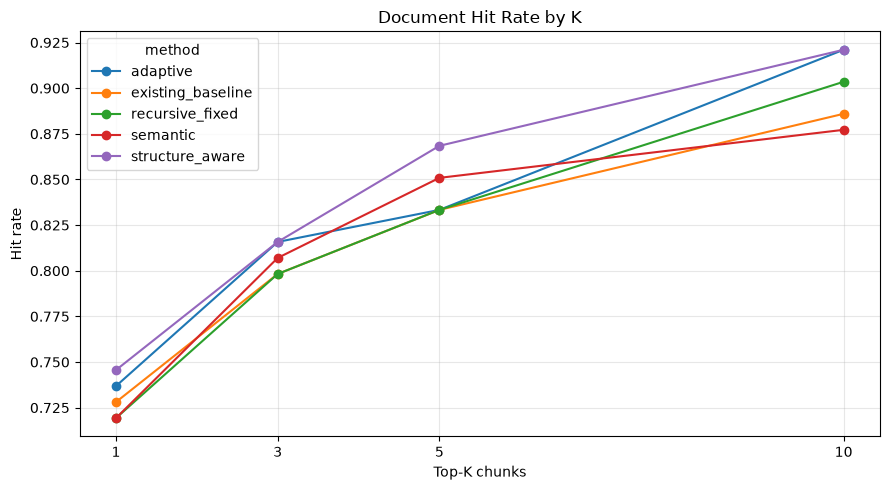

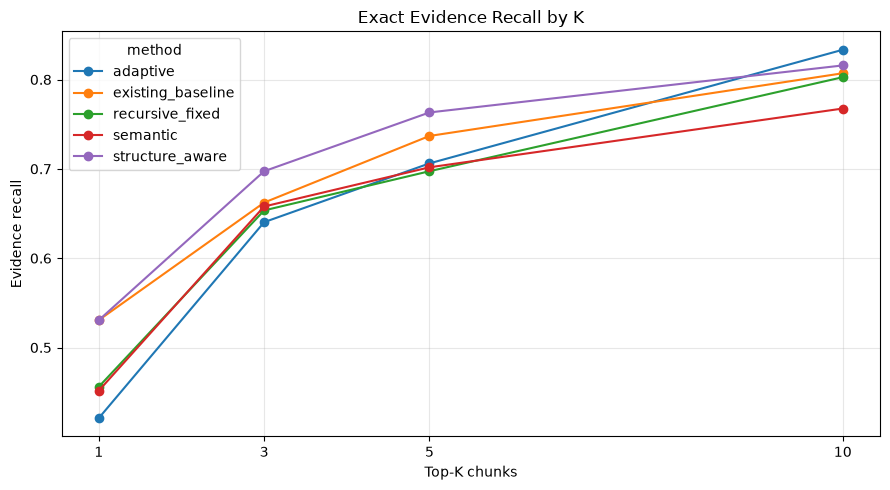

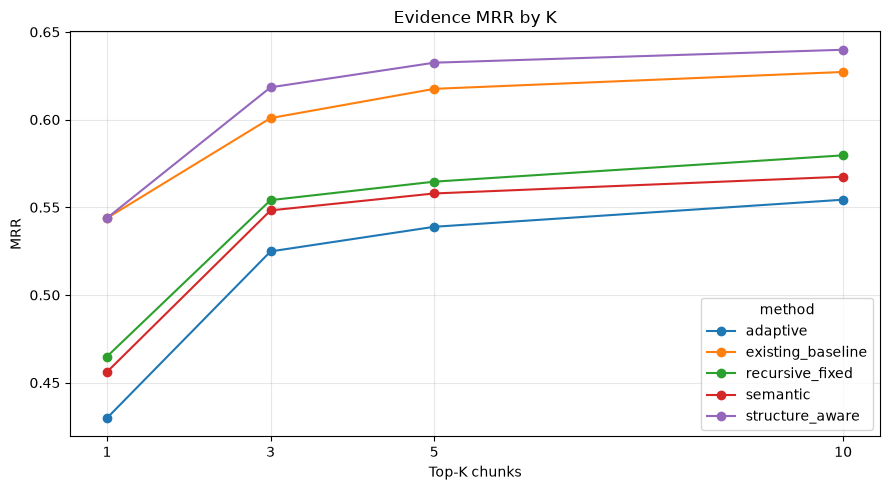

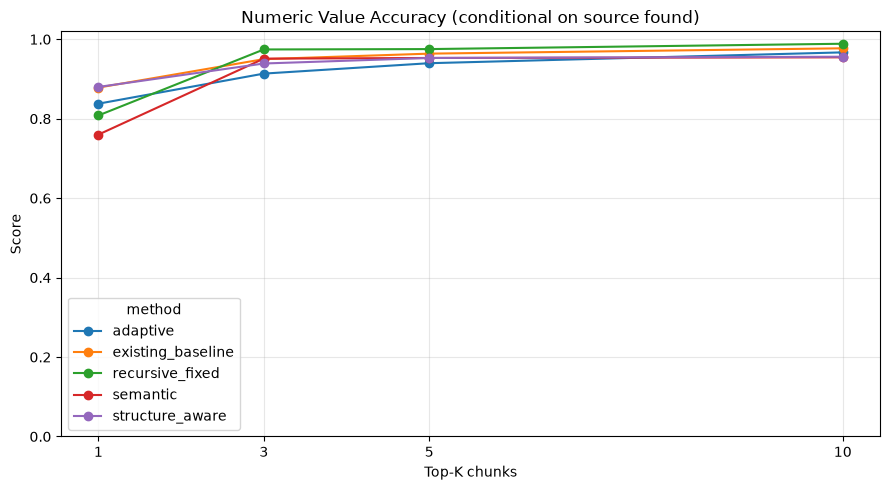

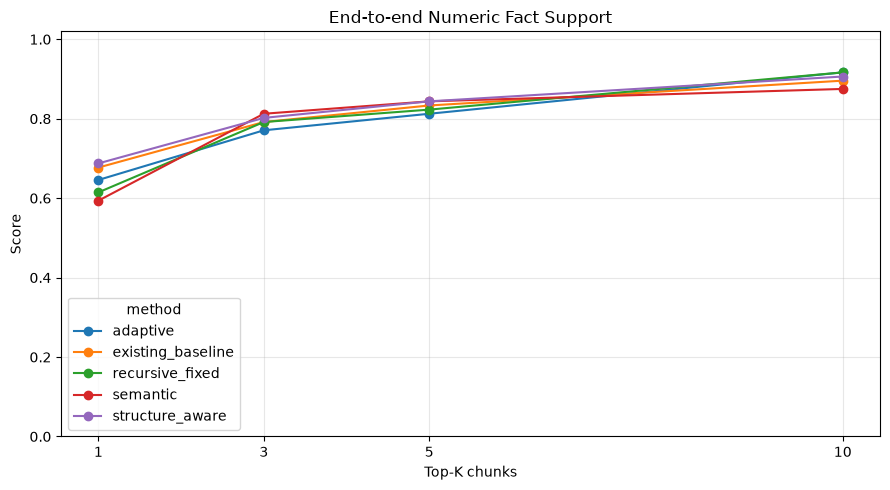

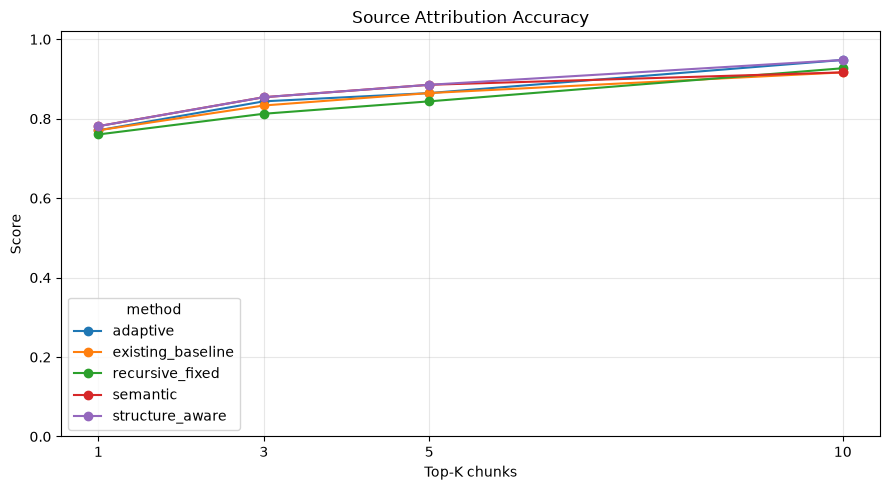

In [18]:
for metric, title, ylabel in [
    ("document_hit_rate", "Document Hit Rate by K", "Hit rate"),
    ("evidence_recall", "Exact Evidence Recall by K", "Evidence recall"),
    ("evidence_mrr", "Evidence MRR by K", "MRR"),
]:
    pivot = retrieval_summary_df.pivot(index="k", columns="method", values=metric)
    ax = pivot.plot(marker="o", figsize=(9, 5))
    ax.set_title(title)
    ax.set_xlabel("Top-K chunks")
    ax.set_ylabel(ylabel)
    ax.set_xticks(K_VALUES)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

for metric, title in [
    ("numeric_value_accuracy_conditional", "Numeric Value Accuracy (conditional on source found)"),
    ("numeric_value_support_end_to_end", "End-to-end Numeric Fact Support"),
    ("source_attribution_accuracy", "Source Attribution Accuracy"),
]:
    pivot = fact_summary_df.pivot(index="k", columns="method", values=metric)
    ax = pivot.plot(marker="o", figsize=(9, 5))
    ax.set_title(title)
    ax.set_xlabel("Top-K chunks")
    ax.set_ylabel("Score")
    ax.set_xticks(K_VALUES)
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 14. Inspect Failures

เลือกดู Query ที่ Evidence Recall@10 ต่ำ เพื่อหาสาเหตุ เช่น Evidence ไม่อยู่ใน Corpus, Quote ถูกแบ่งข้าม Chunks หรือ Retrieval หา Chunk ที่มี Source ถูกต้องไม่เจอ

In [19]:
K_FOR_FAILURE_REVIEW = 10
failure_view = query_metrics_df[query_metrics_df["k"] == K_FOR_FAILURE_REVIEW].copy()
# Find query/method rows where no exact quote is found in the Top-K.
failure_view = failure_view[failure_view["evidence_recall"].fillna(0) < 1].sort_values(
    ["method", "evidence_recall", "evidence_mrr", "query_id"]
)

failure_rows = []
for row in failure_view.head(40).to_dict("records"):
    q = query_by_id[row["query_id"]]
    top = rankings[(row["method"], row["query_id"])][:K_FOR_FAILURE_REVIEW]
    failure_rows.append({
        "method": row["method"],
        "query_id": row["query_id"],
        "split": q.get("split"),
        "query_type": q.get("query_type"),
        "query": q.get("query"),
        "expected_documents": ";".join(sorted(get_expected_docs(q))),
        "evidence_quotes": " || ".join(str(e.get("exact_quote") or "")[:300] for e in (q.get("evidence") or [])),
        "top10_retrieved": " || ".join(
            f"rank {ch['rank']} [{ch.get('document_id')}] score={ch.get('score', 0):.3f}: {str(ch.get('content',''))[:220]}"
            for ch in top[:5]
        ),
        "document_hit_at_10": row["document_hit"],
        "evidence_recall_at_10": row["evidence_recall"],
    })
failure_analysis_df = pd.DataFrame(failure_rows)
display(failure_analysis_df.head(20))


,method,query_id,split,query_type,query,expected_documents,evidence_quotes,top10_retrieved,document_hit_at_10,evidence_recall_at_10
0,adaptive,gtv2_000051,test,economic_explanation,แถลงการณ์ FOMC วันที่ 2014-07-30 อธิบายภาวะเงินเฟ้อในขณะนั้นไว้อย่างไร?,710668d3628dd0eb0c8c2eb25fc593cce92113f2,The Committee sees the risks to the outlook for economic activity and the labor market as nearly balanced and judges that the likelihood of inflation runnin...,"rank 1 [43f04a08ed541ab5229dc45fb342961d3a5fb875] score=0.636: could pose risks to economic performance, and it is monitoring inflation developments careful...",1,0.0
1,adaptive,gtv2_000053,validation,economic_explanation,How did the FOMC statement dated 2014-06-18 characterize inflation conditions at that time?,43f04a08ed541ab5229dc45fb342961d3a5fb875,"Inflation has been running below the Committee's longer-run objective, but longer-term inflation expectations have remained stable.",rank 1 [4a774823b378271c4a4bf9480f59d5d70470b841] score=0.629: a moderate pace and labor market conditions will remain strong. Inflation on a 12‑month basis...,0,0.0
2,adaptive,gtv2_000055,development,economic_explanation,แถลงการณ์ FOMC วันที่ 2016-11-02 อธิบายภาวะเงินเฟ้อในขณะนั้นไว้อย่างไร?,425fb34a8a5f6065d8caa1a7da108d2b3f5ee7f0,Inflation is expected to rise to 2 percent over the medium term as the transitory effects of past declines in energy and import prices dissipate and the lab...,"rank 1 [ef372ef4294d00c540b11783e6f2c94b06a02a36] score=0.633: broad-based and inclusive goal and reports that its policy decision will be informed by its ""...",1,0.0
3,adaptive,gtv2_000058,test,numeric_fact,What target range for the federal funds rate did the FOMC state on 2018-09-26?,829e09b5a3775fe569f696910d1573aa03c70f0a,"In view of realized and expected labor market conditions and inflation, the Committee decided to raise the target range for the federal funds rate to 2 to 2...","rank 1 [dc8ee5b35a20f0c7f3c4f48276ac03ab86d74b2d] score=0.683: of future adjustments to the target range for the federal funds rate, the Committee will asse...",0,0.0
4,adaptive,gtv2_000059,test,economic_explanation,แถลงการณ์ FOMC วันที่ 2018-09-26 อธิบายภาวะเงินเฟ้อในขณะนั้นไว้อย่างไร?,829e09b5a3775fe569f696910d1573aa03c70f0a,"On a 12-month basis, both overall inflation and inflation for items other than food and energy remain near 2 percent.","rank 1 [829e09b5a3775fe569f696910d1573aa03c70f0a] score=0.636: and inflation expectations, and readings on financial and international developments.\nVoting...",1,0.0
5,adaptive,gtv2_000060,validation,numeric_fact,ในแถลงการณ์ FOMC วันที่ 2019-09-18 คณะกรรมการกำหนดหรือคงช่วงเป้าหมาย federal funds rate ไว้ที่เท่าใด?,dc8ee5b35a20f0c7f3c4f48276ac03ab86d74b2d,"In light of the implications of global developments for the economic outlook as well as muted inflation pressures, the Committee decided to lower the target...","rank 1 [dc8ee5b35a20f0c7f3c4f48276ac03ab86d74b2d] score=0.701: of future adjustments to the target range for the federal funds rate, the Committee will asse...",1,0.0
6,adaptive,gtv2_000061,validation,economic_explanation,How did the FOMC statement dated 2019-09-18 characterize inflation conditions at that time?,dc8ee5b35a20f0c7f3c4f48276ac03ab86d74b2d,"On a 12-month basis, overall inflation and inflation for items other than food and energy are running below 2 percent.",rank 1 [4a774823b378271c4a4bf9480f59d5d70470b841] score=0.640: a moderate pace and labor market conditions will remain strong. Inflation on a 12‑month basis...,1,0.0
7,adaptive,gtv2_000062,test,numeric_fact,What target range for the federal funds rate did the FOMC state on 2019-01-30?,7c0712c74ff8b92d84ac9e7f2b9bcb5171600c15,"In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 2-1/4 to 2-1/2 percent.","rank 1 [dc8ee5b35a20f0c7f3c4f48276ac03ab86d74b2d] score=0.702: of future adjustments to the target range for the federal funds rate, the Committee will asse..."

## 15. Export Results

ผลลัพธ์ทั้งหมดจะบันทึกไว้ที่ `embedding/retrieval_eval_v2/` และ Ground Truth ต้นฉบับจะไม่ถูกแก้ไข

In [20]:
# Save primary outputs
coverage_summary.to_csv(OUTPUT_DIR / "corpus_evidence_coverage_summary.csv", index=False, encoding="utf-8-sig")
evidence_coverage_df.to_csv(OUTPUT_DIR / "evidence_coverage_by_span.csv", index=False, encoding="utf-8-sig")
query_coverage_df.to_csv(OUTPUT_DIR / "query_document_coverage.csv", index=False, encoding="utf-8-sig")
retrieval_summary_df.to_csv(OUTPUT_DIR / "retrieval_metrics_summary.csv", index=False, encoding="utf-8-sig")
query_metrics_df.to_csv(OUTPUT_DIR / "retrieval_metrics_by_query.csv", index=False, encoding="utf-8-sig")
fact_summary_df.to_csv(OUTPUT_DIR / "fact_support_metrics_summary.csv", index=False, encoding="utf-8-sig")
fact_metrics_df.to_csv(OUTPUT_DIR / "fact_support_metrics_by_fact.csv", index=False, encoding="utf-8-sig")
stratified_summary.to_csv(OUTPUT_DIR / "metrics_by_query_type.csv", index=False, encoding="utf-8-sig")
language_summary.to_csv(OUTPUT_DIR / "metrics_by_language.csv", index=False, encoding="utf-8-sig")
split_summary.to_csv(OUTPUT_DIR / "metrics_by_split.csv", index=False, encoding="utf-8-sig")
predictions_df.to_json(OUTPUT_DIR / "retrieval_predictions.jsonl", orient="records", lines=True, force_ascii=False)
failure_analysis_df.to_csv(OUTPUT_DIR / "failure_analysis_top40.csv", index=False, encoding="utf-8-sig")

manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "ground_truth_path": str(GT_PATH),
    "ground_truth_query_count_loaded": len(queries),
    "query_count_common_corpus_across_all_methods": len(queries_eval),
    "structured_facts_total": len(fact_inventory),
    "structured_facts_excluded_due_to_unresolved_source": len(unresolved_facts_df),
    "methods": METHODS,
    "chunk_dir": str(CHUNK_DIR),
    "chunk_counts": {m: len(chunk_sets[m]) for m in METHODS},
    "document_counts": {m: len(chunks_by_method_doc[m]) for m in METHODS},
    "embedding_model": EMBEDDING_MODEL,
    "retrieval": "Exact cosine similarity over local chunk embeddings; stable tie-break by original chunk order",
    "k_values": K_VALUES,
    "apply_gold_source_filter": APPLY_GOLD_SOURCE_FILTER,
    "splits_to_evaluate": sorted(SPLITS_TO_EVALUATE) if SPLITS_TO_EVALUATE else "all",
    "ground_truth_review_statuses": query_summary["review_status"].value_counts(dropna=False).to_dict(),
    "note": "Provisional results. Ground Truth requires human semantic review; relevance judgments are non-exhaustive. Do not interpret known-evidence precision as exhaustive precision.",
    "chunk_vector_files": chunk_vector_paths,
}
(OUTPUT_DIR / "experiment_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

summary_md = f"""# Gold Assistant Retrieval Evaluation Summary\n\n- Queries loaded: {len(queries)}\n- Queries with source-document coverage across all methods: {len(queries_eval)}\n- Methods: {', '.join(METHODS)}\n- Embedding: {EMBEDDING_MODEL}\n- K values: {K_VALUES}\n- Ground Truth semantic review: pending; provisional results only\n\n## Retrieval metrics\n\n{retrieval_summary_df.round(4).to_markdown(index=False)}\n\n## Fact support metrics\n\n{fact_summary_df.round(4).to_markdown(index=False)}\n\n**Caveat:** Ground Truth v2 is not human-verified and relevance judgments are non-exhaustive. Exact span support is stricter than document-level retrieval.\n"""
(OUTPUT_DIR / "benchmark_summary.md").write_text(summary_md, encoding="utf-8")

print("Saved results to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.glob("*")):
    if path.is_file():
        print(f"{path.name:45s} {path.stat().st_size:,} bytes")


Saved results to: D:\Project_Github\gold assisstant\embedding\embedding\retrieval_eval_v2
benchmark_summary.md                          13,605 bytes
cloudflare_embedding_cache.sqlite             96,817,152 bytes
corpus_evidence_coverage_summary.csv          564 bytes
evidence_coverage_by_span.csv                 51,250 bytes
experiment_manifest.json                      2,226 bytes
fact_support_metrics_by_fact.csv              315,413 bytes
fact_support_metrics_summary.csv              2,913 bytes
failure_analysis_top40.csv                    76,574 bytes
metrics_by_language.csv                       3,247 bytes
metrics_by_query_type.csv                     7,669 bytes
metrics_by_split.csv                          4,568 bytes
query_document_coverage.csv                   32,600 bytes
retrieval_metrics_by_query.csv                185,944 bytes
retrieval_metrics_summary.csv                 2,836 bytes
retrieval_predictions.jsonl                   12,977,711 bytes
vectors_adaptive_cf_baai

## 16. Interpretation Checklist

ก่อนสรุปว่า Method ใดดีที่สุด ให้ตรวจ:

1. Queries ที่มี Source Document ครบในทุก Method มีจำนวนมากพอหรือไม่
2. `quote_in_single_chunk` ต่ำผิดปกติหรือไม่ — อาจบอกว่า Chunking ตัด Evidence ออกจากกัน
3. `document_hit_rate` สูง แต่ `evidence_recall` ต่ำหรือไม่ — แปลว่าค้นถูกเอกสารแต่ไม่ได้ข้อความสนับสนุนที่ถูกต้อง
4. `numeric_value_accuracy_conditional` สูง แต่ `source_attribution_accuracy` ต่ำหรือไม่ — Conditional Accuracy อย่างเดียวจะทำให้ผลดูดีกว่าความสามารถ end-to-end
5. Query type, language และ split ใดได้ตัวอย่างน้อยเกินไปหรือไม่
6. ตรวจ Failure CSV และทำ Human Review ของ Ground Truth ก่อนใช้คะแนนเลือก Method สุดท้าย

**ข้อจำกัด:** Notebook นี้ทดสอบ Embedding Retrieval และ Fact Support จาก Chunks เท่านั้น ไม่ได้ทดสอบ LLM answer generation และไม่พิสูจน์ความเป็นเหตุเป็นผลระหว่างข่าวเศรษฐกิจกับราคาทองคำ